# 04 · Preparación para el modelado

**Entradas:** `datos/incidencias_limpias.csv` (con microzona), `datos/microzonas.geojson`, métricas de 01–03.
**Salidas:** `datos/gravedad_por_tipo.csv`, `datos/tabla_modelado.csv`, `datos/metricas_modelado.json` y `handoff_fase2.json`.

Contenido: partición temporal, gravedad G, tabla `microzona × fecha × turno` con ceros, objetivo `nivel`, variables sin fuga y su
auditoría programática, línea base de persistencia (Macro F1 **solo en validación**) y contexto SIDPOL.
**Prueba (5–8 jun): solo se cuentan filas y clases.**

In [1]:
import json
from datetime import datetime, timezone, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.metrics import f1_score, confusion_matrix, classification_report, accuracy_score
from _comun import *
from _features import FEATURES, construir_tabla, nivel_desde_conteo

configurar_estilo()
np.random.seed(SEMILLA)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

df = cargar_limpias()
geo = json.loads((DATOS / "microzonas.geojson").read_text(encoding="utf-8"))
mz = pd.DataFrame([f["properties"] for f in geo["features"]])[["id_microzona", "col", "fila"]]
m_cal = json.loads((DATOS / "metricas_calidad.json").read_text(encoding="utf-8"))
m_tem = json.loads((DATOS / "metricas_temporal.json").read_text(encoding="utf-8"))
m_esp = json.loads((DATOS / "metricas_espacial.json").read_text(encoding="utf-8"))
print(f"Incidencias limpias: {len(df)} · microzonas activas: {len(mz)} ({m_esp['tamano_elegido_m']} m)")

Incidencias limpias: 2580 · microzonas activas: 86 (500 m)


## 1. Partición temporal
Ventana utilizable: **22 may – 8 jun (18 días completos)**. Se excluyen el arranque (16–21 may, solo historial para rezagos) y los días
censurados (9–10 jun), según `01_calidad`. Opciones evaluadas (todas contiguas, sin solapamiento, días completos):

In [2]:
VENTANA = fechas_rango(INICIO_ESTABLE, FIN_ESTABLE)
def describir(nombre, tr, va, te):
    filas = []
    for part, (i, f) in zip(["train", "valid", "test"], [tr, va, te]):
        d = pd.date_range(i, f)
        filas.append(f"{part}: {i[5:]}→{f[5:]} ({len(d)} d, {int((d.dayofweek >= 5).sum())} de fin de semana)")
    return {"opcion": nombre, "detalle": " | ".join(filas), "dias_train": len(pd.date_range(*tr))}
opciones = pd.DataFrame([
    describir("O1 · 10/4/4 (propuesta del alcance: ~4 valid + 4 prueba)", PARTICION["train"], PARTICION["valid"], PARTICION["test"]),
    describir("O2 · 7/7/4 (validación de semana completa)", ("2026-05-22", "2026-05-28"), ("2026-05-29", "2026-06-04"), ("2026-06-05", "2026-06-08")),
    describir("O3 · 4/7/7 (validación y prueba de semana completa)", ("2026-05-22", "2026-05-25"), ("2026-05-26", "2026-06-01"), ("2026-06-02", "2026-06-08")),
])
print(opciones.to_string(index=False))
for p, (i, f) in PARTICION.items():
    print(f"{p:5s}: {i} → {f} ({len(fechas_rango(i, f))} días)")
assert fechas_rango(PARTICION["train"][0], PARTICION["test"][1]) == VENTANA

                                                  opcion                                                                                                                                    detalle  dias_train
O1 · 10/4/4 (propuesta del alcance: ~4 valid + 4 prueba) train: 05-22→05-31 (10 d, 4 de fin de semana) | valid: 06-01→06-04 (4 d, 0 de fin de semana) | test: 06-05→06-08 (4 d, 2 de fin de semana)          10
              O2 · 7/7/4 (validación de semana completa)  train: 05-22→05-28 (7 d, 2 de fin de semana) | valid: 05-29→06-04 (7 d, 2 de fin de semana) | test: 06-05→06-08 (4 d, 2 de fin de semana)           7
     O3 · 4/7/7 (validación y prueba de semana completa)  train: 05-22→05-25 (4 d, 2 de fin de semana) | valid: 05-26→06-01 (7 d, 2 de fin de semana) | test: 06-02→06-08 (7 d, 2 de fin de semana)           4
train: 2026-05-22 → 2026-05-31 (10 días)
valid: 2026-06-01 → 2026-06-04 (4 días)
test : 2026-06-05 → 2026-06-08 (4 días)


**Decisión: O1.** Entrenamiento 22–31 may (10 días: una semana completa lun–dom más vie–dom), validación 1–4 jun (4 días, lun–jue) y
prueba 5–8 jun (4 días, vie–lun; los últimos días completos). Con 18 días no caben dos semanas completas sin dejar al entrenamiento con
4 días (O3); O2 da una validación de semana completa pero deja 7 días de entrenamiento, todos en el tramo de menor cobertura (~99/día),
del que saldrían los umbrales y las celdas activas. O1 es además la propuesta inicial del alcance (≈ 4 + 4 días).
**Coste conocido:** la validación no contiene fin de semana y la prueba sí (sáb–dom y el feriado del 7 jun); la Fase 3 debe reportar
métricas por día y por turno además del agregado.

## 2. Gravedad G por tipo y subtipo (**supuesto de diseño**)
Escala ordinal de 1 a 5 por tipo, según la naturaleza de la conducta reportada y el daño potencial a personas, siguiendo el orden propuesto
para el proyecto: actividad presuntamente delictiva > faltas > infracciones > alertas de infraestructura y riesgo > apoyo/operativos.
No es una medición del daño real ni proviene de la fuente (la columna `NIVEL` de la fuente es [POST] y no se usa). `G_norm = (G − 1) / 4`.

In [3]:
G_TIPO = {
    "Presuntamente delictivas": (5, "Alerta de conducta presuntamente delictiva (patrimonio, vida/cuerpo/salud, libertad): mayor daño potencial a personas; activa a la PNP."),
    "Presuntas faltas": (4, "Conducta que el CCO tipifica como presunta falta (contra la persona, la seguridad o tranquilidad pública, buenas costumbres): afecta a terceros, menor entidad que un delito."),
    "Presuntas infracciones": (3, "Presunta infracción administrativa (ordenanzas, licencias, tránsito, orden público): afecta la convivencia; competencia municipal."),
    "Infraestructura y riesgo": (2, "Alerta sobre infraestructura, servicios o espacios públicos afectados o en riesgo, o desastres: riesgo situacional sin conducta imputada."),
    "Operativos": (1, "Actividad planificada de la propia municipalidad; refleja esfuerzo institucional, no un evento adverso."),
    "Ayuda y apoyo": (1, "Apoyo a personas, gerencias o entidades: servicio; la ayuda/rescate de personas se mantiene en 1 por coherencia con el tipo (40 registros)."),
    "Acontecimientos especiales": (1, "Subtipo sin descripción en el diccionario oficial (10 registros); se asigna el mínimo por prudencia."),
}
gravedad = (df.groupby(["tipo", "tipo_corto", "subtipo", "subtipo_norm"]).size().rename("registros").reset_index())
gravedad["gravedad"] = gravedad.tipo_corto.map(lambda t: G_TIPO[t][0])
gravedad["gravedad_norm"] = ((gravedad.gravedad - 1) / 4).round(2)
gravedad["justificacion"] = gravedad.tipo_corto.map(lambda t: G_TIPO[t][1])
gravedad["supuesto_de_diseno"] = True
gravedad = gravedad.sort_values(["gravedad", "registros"], ascending=[False, False]).reset_index(drop=True)
gravedad.to_csv(DATOS / "gravedad_por_tipo.csv", index=False, encoding="utf-8")
print(gravedad[["tipo_corto", "subtipo_norm", "registros", "gravedad", "gravedad_norm"]].to_string(index=False))
df = df.merge(gravedad[["tipo", "subtipo", "gravedad"]], on=["tipo", "subtipo"], how="left", validate="many_to_one")
assert df.gravedad.notna().all()

                tipo_corto                                                    subtipo_norm  registros  gravedad  gravedad_norm
  Presuntamente delictivas                      PRESUNTAS ACTIVIDADES CONTRA EL PATRIMONIO         32         5           1.00
  Presuntamente delictivas                                PRE. ACTIV. CONTRA LA SALUD PUB.          6         5           1.00
  Presuntamente delictivas       PRESUNTAS ACTIVIDADES CONTRA LA VIDA EL CUERPO Y LA SALUD          6         5           1.00
  Presuntamente delictivas                   PRESUNTA ACTIVIDAD CONTRA LA TRANQUILIDAD PUB          4         5           1.00
  Presuntamente delictivas                           PRESUNTA ACTIVIDAD CONTRA LA LIBERTAD          2         5           1.00
  Presuntamente delictivas                       PRESUNTAS ACTIVIDADES CONTRA LA SEG. PUB.          1         5           1.00
          Presuntas faltas                    PRESUNTA ACTIV. CONTRA LAS BUENAS COSTUMBRES        323         4

## 3. Variable objetivo `nivel` y tabla de modelado
**Unidad:** microzona activa × fecha × turno, **incluyendo ceros**, para las 18 fechas de la ventana.
**Regla:** `conteo` = nº de incidencias limpias registradas en la microzona, fecha y turno. `Bajo` si conteo = 0; `Medio` si 1 ≤ conteo ≤ b;
`Alto` si conteo > b, donde **b = mediana de los conteos positivos de entrenamiento** (redondeada al entero; los conteos son enteros).

In [4]:
hist = df[df.fecha <= FIN_ESTABLE]                      # historia utilizable (arranque incluido, censura excluida)
tabla = construir_tabla(hist, mz, VENTANA, b=None)      # primero sin umbral, para calcular b solo con entrenamiento
tabla["particion"] = particion_de(tabla.fecha)
pos_train = tabla.loc[(tabla.particion == "train") & (tabla.conteo > 0), "conteo"]
B = float(np.median(pos_train))
print(f"Conteos positivos en entrenamiento: {len(pos_train)} · mediana b = {B:g} · distribución:", pos_train.value_counts().sort_index().to_dict())
tabla["nivel"] = nivel_desde_conteo(tabla.conteo, B)
tabla["nivel_lag1_turno"] = nivel_desde_conteo(tabla.lag1_turno, B)
n_esperado = len(mz) * len(VENTANA) * 3
assert len(tabla) == n_esperado, (len(tabla), n_esperado)
assert not tabla.duplicated(["id_microzona", "fecha", "turno"]).any()
columnas = ["id_microzona", "mz_col", "mz_fila", "fecha", "turno", "particion"] + [f for f in FEATURES if f != "turno"] + ["conteo", "nivel"]
tabla = tabla[columnas].sort_values(["fecha", "turno", "id_microzona"], key=lambda s: s.map({t: i for i, t in enumerate(TURNOS)}) if s.name == "turno" else s).reset_index(drop=True)
tabla.to_csv(DATOS / "tabla_modelado.csv", index=False, encoding="utf-8")
print(f"Tabla de modelado: {len(tabla)} filas = {len(mz)} microzonas × {len(VENTANA)} fechas × 3 turnos · ceros: {pct((tabla.conteo == 0).mean() * 100)}")
print(tabla.head(3).T.to_string())

Conteos positivos en entrenamiento: 722 · mediana b = 1 · distribución: {1: 480, 2: 146, 3: 57, 4: 20, 5: 8, 6: 3, 7: 5, 8: 2, 11: 1}
Tabla de modelado: 4644 filas = 86 microzonas × 18 fechas × 3 turnos · ceros: 71,1 %
                                0           1           2
id_microzona              MZ-0001     MZ-0002     MZ-0003
mz_col                          6           8           9
mz_fila                        15          15          15
fecha                  2026-05-22  2026-05-22  2026-05-22
turno                      Mañana      Mañana      Mañana
particion                   train       train       train
lag1_turno                      0           0           0
lag7_turno                   <NA>        <NA>        <NA>
suma3_turno                     0           0           0
media7_turno                  0.0         0.0         0.0
lag1_celda                      0           0           0
suma7_celda                     0           0           0
dias_desde_ultima          

Filas por partición y clase (conteo):
        Bajo  Medio  Alto  total
train  1858    480   242   2580
valid   756    172   104   1032
test    686    204   142   1032

% por partición:
        Bajo  Medio  Alto
train  72.0   18.6   9.4
valid  73.3   16.7  10.1
test   66.5   19.8  13.8

Razón Bajo/Alto en entrenamiento: 7.7 : 1


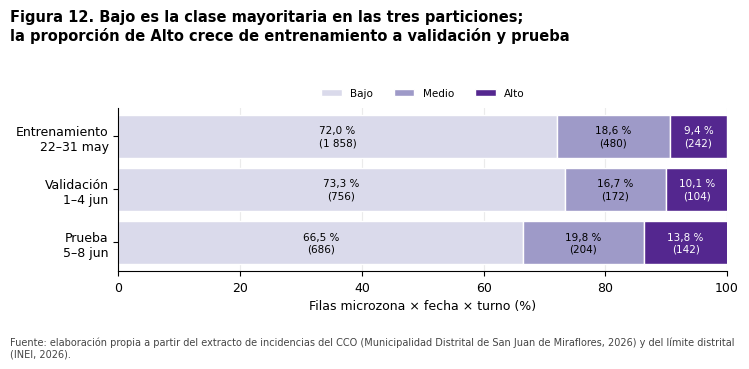

WindowsPath('C:/Users/Ghino/Desktop/prototipo-practicas-pre/02_documentacion/02_analisis/figuras/fig12_clases_por_particion.png')

In [5]:
dist = {}
for p in ["train", "valid", "test"]:
    vc = tabla.loc[tabla.particion == p, "nivel"].value_counts().reindex(NIVELES, fill_value=0)
    dist[p] = {n: int(v) for n, v in vc.items()}
dist_df = pd.DataFrame(dist).T
dist_pct = (dist_df.div(dist_df.sum(1), axis=0) * 100).round(1)
print("Filas por partición y clase (conteo):\n", dist_df.assign(total=dist_df.sum(1)).to_string())
print("\n% por partición:\n", dist_pct.to_string())
desbalance = dist_df.loc["train", "Bajo"] / dist_df.loc["train", "Alto"]
print(f"\nRazón Bajo/Alto en entrenamiento: {desbalance:.1f} : 1")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
izq = np.zeros(3)
etiquetas = {"train": "Entrenamiento\n22–31 may", "valid": "Validación\n1–4 jun", "test": "Prueba\n5–8 jun"}
for n in NIVELES:
    vals = dist_pct[n].values
    ax.barh([etiquetas[p] for p in dist_pct.index], vals, left=izq, color=COLOR_NIVEL[n], label=n, edgecolor="white")
    for y, (v, l) in enumerate(zip(vals, izq)):
        if v >= 4:
            ax.text(l + v / 2, y, f"{fmt(v, 1)} %\n({fmt(dist_df.loc[dist_pct.index[y], n])})", ha="center", va="center", fontsize=7.5,
                    color="white" if n == "Alto" else "black")
    izq += vals
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("Filas microzona × fecha × turno (%)"); eje_es(ax, "x", 0)
ax.legend(ncol=3, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
guardar_figura(fig, "fig12_clases_por_particion.png", 12,
               "Bajo es la clase mayoritaria en las tres particiones;\nla proporción de Alto crece de entrenamiento a validación y prueba",
               FUENTE_CCO_LIMITE)

## 4. Variables candidatas y auditoría de fuga
Todas se calculan con incidencias de fechas **estrictamente anteriores** a la fecha objetivo (información disponible al cierre del día d−1),
así que la predicción puede emitirse antes de que empiece cualquier turno del día d. La historia incluye el arranque (16–21 may).

In [6]:
DESCRIPCION = {
    "lag1_turno": ("Incidencias en la microzona, mismo turno, día d−1", "d−1", "historial"),
    "lag7_turno": ("Incidencias en la microzona, mismo turno, día d−7 (vacío si d−7 < 16 may: solo el 22 may)", "d−7", "historial"),
    "suma3_turno": ("Suma en la microzona, mismo turno, días d−3 a d−1", "d−3…d−1", "historial"),
    "media7_turno": ("Media diaria en la microzona, mismo turno, días d−7 a d−1 (días disponibles desde el 16 may)", "d−7…d−1", "historial"),
    "lag1_celda": ("Incidencias en la microzona, todos los turnos, día d−1", "d−1", "historial"),
    "suma7_celda": ("Suma en la microzona, todos los turnos, días d−7 a d−1", "d−7…d−1", "historial"),
    "dias_desde_ultima": ("Días desde el último día con registro en la microzona (tope 14)", "16 may…d−1", "historial"),
    "gravedad_media7_celda": ("Gravedad media G (1–5) de las incidencias de la microzona en d−7 a d−1 (0 si no hubo)", "d−7…d−1", "historial"),
    "nivel_lag1_turno": ("Nivel (Bajo/Medio/Alto) de lag1_turno con el umbral b de entrenamiento", "d−1", "historial"),
    "vecinos_lag1_turno": ("Incidencias en las 8 celdas vecinas, mismo turno, día d−1", "d−1", "espacial"),
    "vecinos_suma7": ("Suma en las 8 celdas vecinas, todos los turnos, días d−7 a d−1", "d−7…d−1", "espacial"),
    "dia_semana": ("Día de la semana de d (0 = lunes)", "d (calendario)", "calendario"),
    "fin_de_semana": ("1 si d es sábado o domingo", "d (calendario)", "calendario"),
    "feriado": ("1 si d es feriado nacional (7 jun, Ley N.° 31788)", "d (calendario)", "calendario"),
    "turno": ("Turno objetivo (Mañana, Tarde, Noche)", "d (calendario)", "calendario"),
    "distrito_lag1_turno": ("Incidencias en todo el distrito, mismo turno, día d−1", "d−1", "contexto"),
    "distrito_lag1": ("Incidencias en todo el distrito, día d−1", "d−1", "contexto"),
    "distrito_media7": ("Media diaria de incidencias del distrito en d−7 a d−1 (nivel de cobertura reciente)", "d−7…d−1", "contexto"),
}
assert set(DESCRIPCION) == set(FEATURES)
POR_QUE = {"historial": "Usa solo incidencias registradas antes de la fecha objetivo (ventana termina en d−1).",
           "espacial": "Agrega celdas vecinas con la misma ventana rezagada (termina en d−1); no usa el periodo objetivo.",
           "calendario": "Se conoce de antemano para cualquier fecha futura; no depende de incidencias.",
           "contexto": "Total del distrito con ventana que termina en d−1; capta el cambio de cobertura sin mirar el periodo objetivo."}
features_spec = [{"nombre": f, "descripcion": DESCRIPCION[f][0], "ventana": DESCRIPCION[f][1], "tipo": DESCRIPCION[f][2],
                  "sin_fuga_porque": POR_QUE[DESCRIPCION[f][2]] + (" El umbral b se fija con entrenamiento." if f == "nivel_lag1_turno" else "")}
                 for f in FEATURES]
print(pd.DataFrame(features_spec)[["nombre", "tipo", "ventana"]].to_string(index=False))

EXCLUIDAS = ["estado_final", "fecha_hora_cierre", "tiempo_respuesta_min", "NIVEL", "conteo", "nivel"]
print("\nExcluidas por fuga:", EXCLUIDAS)
print("  - estado_final, fecha_hora_cierre, tiempo_respuesta_min: [POST], se conocen al cierre (ni siquiera están en el dataset limpio).")
print("  - NIVEL (fuente): gravedad asignada durante la coordinación [POST]; no está en el canónico.")
print("  - conteo y nivel: son el objetivo de la misma fecha-turno.")
print("  - Cualquier agregado de canal, tipo o gravedad de la misma fecha-turno o posterior.")

               nombre       tipo        ventana
           lag1_turno  historial            d−1
           lag7_turno  historial            d−7
          suma3_turno  historial        d−3…d−1
         media7_turno  historial        d−7…d−1
           lag1_celda  historial            d−1
          suma7_celda  historial        d−7…d−1
    dias_desde_ultima  historial     16 may…d−1
gravedad_media7_celda  historial        d−7…d−1
     nivel_lag1_turno  historial            d−1
   vecinos_lag1_turno   espacial            d−1
        vecinos_suma7   espacial        d−7…d−1
           dia_semana calendario d (calendario)
        fin_de_semana calendario d (calendario)
              feriado calendario d (calendario)
                turno calendario d (calendario)
  distrito_lag1_turno   contexto            d−1
        distrito_lag1   contexto            d−1
      distrito_media7   contexto        d−7…d−1

Excluidas por fuga: ['estado_final', 'fecha_hora_cierre', 'tiempo_respuesta_min', 'NIVE

In [7]:
# Prueba programática de no fuga: para cada fecha objetivo d, recalcular las variables usando SOLO la historia con fecha < d
# y verificar que coinciden exactamente con las de la tabla completa. Si alguna variable usara datos de d o posteriores, cambiaría.
rng = np.random.default_rng(SEMILLA)
comparables = [f for f in FEATURES if f != "turno"]
fallos = []
for d in VENTANA:
    trunc = construir_tabla(hist[hist.fecha < d], mz, [d], b=B, incluir_objetivo=False)
    # perturbación adicional: inyectar incidencias falsas en d y d+1 (si existe) no debe cambiar nada
    falsas = hist[hist.fecha < d].sample(50, random_state=SEMILLA).assign(fecha=d)
    pert = construir_tabla(pd.concat([hist[hist.fecha < d], falsas]), mz, [d], b=B, incluir_objetivo=False)
    ref = tabla[tabla.fecha == d].set_index(["id_microzona", "turno"])[comparables].sort_index()
    for nombre, t in (("truncada", trunc), ("perturbada", pert)):
        t = t.set_index(["id_microzona", "turno"])[comparables].sort_index()
        a = ref.apply(lambda s: pd.to_numeric(s, errors="coerce") if s.name != "nivel_lag1_turno" else s)
        bb = t.apply(lambda s: pd.to_numeric(s, errors="coerce") if s.name != "nivel_lag1_turno" else s)
        iguales = a.fillna(-999).astype(str).eq(bb.fillna(-999).astype(str)).all()
        if not iguales.all():
            fallos.append((d, nombre, list(iguales[~iguales].index)))
assert not (set(FEATURES) & set(EXCLUIDAS)), "Hay features en la lista de excluidas"
assert not fallos, fallos
print(f"Prueba de no fuga superada: {len(VENTANA)} fechas × 2 escenarios (historia truncada en d; incidencias falsas inyectadas en d), "
      f"{len(comparables)} variables idénticas en las {len(tabla)} filas. Ninguna feature está en excluidas_por_fuga.")
prueba_fuga = {"fechas": len(VENTANA), "escenarios": ["historia truncada en d", "incidencias falsas inyectadas en d"],
               "variables": len(comparables), "resultado": "superada"}

Prueba de no fuga superada: 18 fechas × 2 escenarios (historia truncada en d; incidencias falsas inyectadas en d), 17 variables idénticas en las 4644 filas. Ninguna feature está en excluidas_por_fuga.


In [8]:
print("Valores faltantes por variable:", tabla[FEATURES].isna().sum()[lambda s: s > 0].to_dict())
print("Filas con lag7_turno vacío por fecha:", tabla[tabla.lag7_turno.isna()].fecha.value_counts().to_dict())
tr = tabla[tabla.particion == "train"]
asoc = {f: round(float(tr[[f, "conteo"]].apply(pd.to_numeric, errors="coerce").corr(method="spearman").iloc[0, 1]), 3)
        for f in FEATURES if f not in ("turno", "nivel_lag1_turno", "feriado")}
print("Spearman con el conteo (solo entrenamiento, descriptivo):\n", pd.Series(asoc).sort_values(ascending=False).to_string())
print("feriado: constante 0 en entrenamiento y validación (el único feriado, 7 jun, cae en prueba).")

Valores faltantes por variable: {'lag7_turno': 258}
Filas con lag7_turno vacío por fecha: {'2026-05-22': 258}
Spearman con el conteo (solo entrenamiento, descriptivo):
 suma7_celda              0.346
media7_turno             0.325
suma3_turno              0.314
lag1_celda               0.307
lag1_turno               0.256
vecinos_suma7            0.245
vecinos_lag1_turno       0.243
lag7_turno               0.203
distrito_lag1_turno      0.089
distrito_lag1            0.084
dia_semana               0.080
gravedad_media7_celda    0.078
distrito_media7          0.074
fin_de_semana            0.066
dias_desde_ultima       -0.263
feriado: constante 0 en entrenamiento y validación (el único feriado, 7 jun, cae en prueba).


## 5. Línea base de persistencia (Macro F1 solo en validación)
Predicción: el nivel del **mismo turno del día anterior** en la misma microzona (`nivel_lag1_turno`).

Persistencia · validación: Macro F1 = 0.4390 · exactitud = 0.6357 · filas = 1032
              precision    recall  f1-score   support

        Bajo      0.800     0.769     0.784       756
       Medio      0.220     0.244     0.231       172
        Alto      0.287     0.317     0.301       104

    accuracy                          0.636      1032
   macro avg      0.436     0.443     0.439      1032
weighted avg      0.652     0.636     0.643      1032

Referencia trivial (siempre Bajo) · validación: Macro F1 = 0.2819
Macro F1 por día (validación): {'2026-06-01': 0.337, '2026-06-02': 0.497, '2026-06-03': 0.469, '2026-06-04': 0.467}
Macro F1 por turno (validación): {'Mañana': 0.46, 'Noche': 0.431, 'Tarde': 0.394}


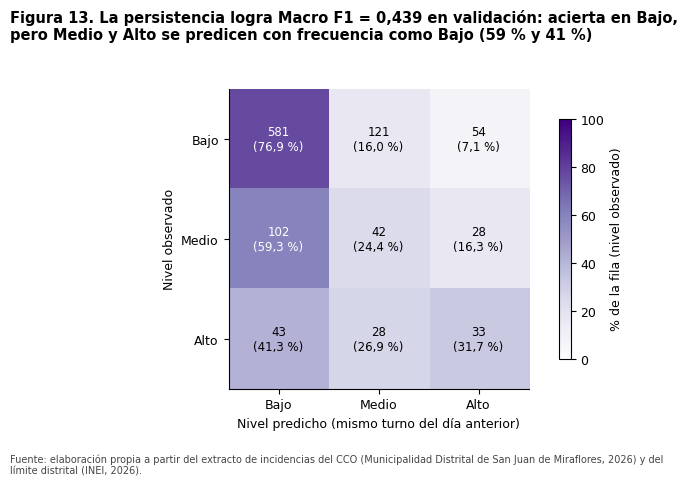

WindowsPath('C:/Users/Ghino/Desktop/prototipo-practicas-pre/02_documentacion/02_analisis/figuras/fig13_matriz_confusion_linea_base.png')

In [9]:
va = tabla[tabla.particion == "valid"].copy()
assert va.nivel_lag1_turno.notna().all()
f1_val = f1_score(va.nivel, va.nivel_lag1_turno, labels=NIVELES, average="macro")
acc_val = accuracy_score(va.nivel, va.nivel_lag1_turno)
cm = confusion_matrix(va.nivel, va.nivel_lag1_turno, labels=NIVELES)
print(f"Persistencia · validación: Macro F1 = {f1_val:.4f} · exactitud = {acc_val:.4f} · filas = {len(va)}")
print(classification_report(va.nivel, va.nivel_lag1_turno, labels=NIVELES, digits=3, zero_division=0))
f1_mayoritaria = f1_score(va.nivel, ["Bajo"] * len(va), labels=NIVELES, average="macro", zero_division=0)
print(f"Referencia trivial (siempre Bajo) · validación: Macro F1 = {f1_mayoritaria:.4f}")
por_dia = va.groupby("fecha")[["nivel", "nivel_lag1_turno"]].apply(lambda g: f1_score(g.nivel, g.nivel_lag1_turno, labels=NIVELES, average="macro", zero_division=0)).round(3)
por_turno = va.groupby("turno")[["nivel", "nivel_lag1_turno"]].apply(lambda g: f1_score(g.nivel, g.nivel_lag1_turno, labels=NIVELES, average="macro", zero_division=0)).round(3)
print("Macro F1 por día (validación):", por_dia.to_dict())
print("Macro F1 por turno (validación):", por_turno.to_dict())
reporte = classification_report(va.nivel, va.nivel_lag1_turno, labels=NIVELES, output_dict=True, zero_division=0)

fig, ax = plt.subplots(figsize=(6.6, 4.8))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
im = ax.imshow(cm_pct, cmap="Purples", vmin=0, vmax=100)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{fmt(cm[i, j])}\n({fmt(cm_pct[i, j], 1)} %)", ha="center", va="center", fontsize=8.5,
                color="white" if cm_pct[i, j] > 55 else "black")
ax.set_xticks(range(3)); ax.set_xticklabels(NIVELES); ax.set_yticks(range(3)); ax.set_yticklabels(NIVELES)
ax.set_xlabel("Nivel predicho (mismo turno del día anterior)"); ax.set_ylabel("Nivel observado"); ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8); cb.set_label("% de la fila (nivel observado)")
guardar_figura(fig, "fig13_matriz_confusion_linea_base.png", 13,
               f"La persistencia logra Macro F1 = {fmt(f1_val, 3)} en validación: acierta en Bajo,\npero Medio y Alto se predicen con frecuencia como Bajo ({fmt(cm_pct[1, 0], 0)} % y {fmt(cm_pct[2, 0], 0)} %)",
               FUENTE_CCO_LIMITE)

## 6. Contexto SIDPOL (no entra al entrenamiento)
Denuncias policiales mensuales de San Juan de Miraflores (MININTER). Sirven para situar el distrito en el tiempo; no tienen ubicación fina
ni turno, no son comparables registro a registro con el CCO y **no se usan como variables del modelo**.

Denuncias por año: {2018: 9592, 2019: 9401, 2020: 6760, 2021: 9215, 2022: 10934, 2023: 13623, 2024: 12876, 2025: 10383, 2026: 7488}
Total 2018-01 a 2026-09: 90 272
Composición últimos 12 meses (2025-10 a 2026-09):
 modalidad
Otros                                      36.6
Violencia contra la mujer e integrantes    35.1
Hurto                                      13.6
Robo                                        7.1
Estafa                                      4.0
Extorsión                                   3.4
Secuestro                                   0.2
Denuncias SIDPOL en mayo y junio de 2026: {'2026-05': 883, '2026-06': 818}


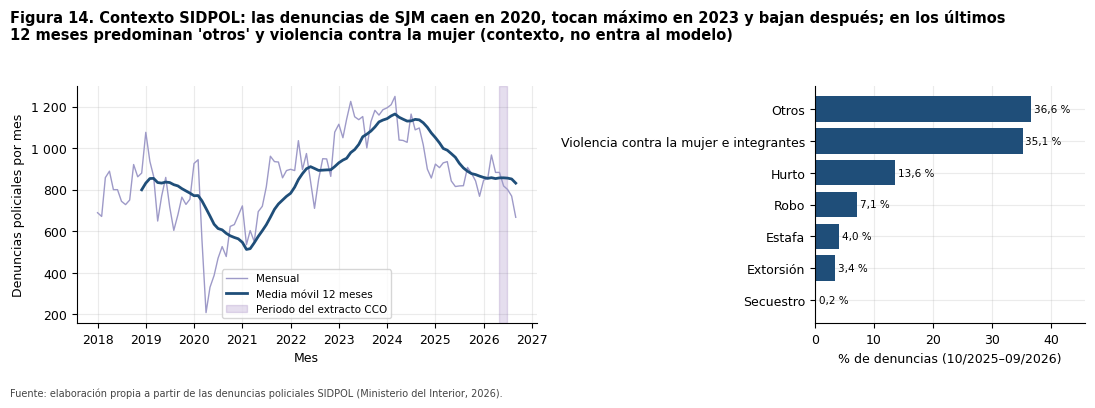

In [10]:
sid = pd.read_csv(SIDPOL, dtype={"ubigeo_inei": str})
sid["periodo"] = pd.to_datetime(dict(year=sid.anio, month=sid.mes, day=1))
mensual = sid.groupby("periodo").cantidad.sum()
anual = sid.groupby("anio").cantidad.sum()
print("Denuncias por año:", anual.to_dict())
print(f"Total 2018-01 a {mensual.index.max():%Y-%m}: {fmt(mensual.sum())}")
ult12 = sid[sid.periodo > mensual.index.max() - pd.DateOffset(months=12)]
comp = ult12.groupby("modalidad").cantidad.sum().sort_values(ascending=False)
comp_pct = (comp / comp.sum() * 100).round(1)
print(f"Composición últimos 12 meses ({ult12.periodo.min():%Y-%m} a {ult12.periodo.max():%Y-%m}):\n", comp_pct.to_string())
may_jun_2026 = mensual.loc["2026-05-01":"2026-06-01"]
print("Denuncias SIDPOL en mayo y junio de 2026:", {f"{k:%Y-%m}": int(v) for k, v in may_jun_2026.items()})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1.7, 1]})
a1.plot(mensual.index, mensual.values, color="#9E9AC8", lw=1, label="Mensual")
a1.plot(mensual.index, mensual.rolling(12).mean(), color=AZUL, lw=2, label="Media móvil 12 meses")
a1.axvspan(pd.Timestamp("2026-05-01"), pd.Timestamp("2026-06-30"), color="#54278F", alpha=0.15, label="Periodo del extracto CCO")
a1.set_ylabel("Denuncias policiales por mes"); a1.set_xlabel("Mes"); a1.legend(fontsize=7.5); eje_es(a1, "y", 0)
a1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
a2.barh(comp_pct.index[::-1], comp_pct.values[::-1], color=AZUL)
for i, v in enumerate(comp_pct.values[::-1]):
    a2.text(v + 0.5, i, f"{fmt(v, 1)} %", va="center", fontsize=7.5)
a2.set_xlabel(f"% de denuncias ({ult12.periodo.min():%m/%Y}–{ult12.periodo.max():%m/%Y})"); eje_es(a2, "x", 0)
a2.set_xlim(0, comp_pct.max() * 1.25)
guardar_figura(fig, "fig14_sidpol_contexto.png", 14,
               "Contexto SIDPOL: las denuncias de SJM caen en 2020, tocan máximo en 2023 y bajan después; en los últimos\n12 meses predominan 'otros' y violencia contra la mujer (contexto, no entra al modelo)",
               FUENTE_SIDPOL)
sidpol = {"periodo": f"{mensual.index.min():%Y-%m} a {mensual.index.max():%Y-%m}", "total": int(mensual.sum()),
          "por_anio": {int(k): int(v) for k, v in anual.items()},
          "composicion_ult12_pct": {k: float(v) for k, v in comp_pct.items()},
          "mayo_junio_2026": {f"{k:%Y-%m}": int(v) for k, v in may_jun_2026.items()}}

## 7. Métricas y handoff para la Fase 3

In [11]:
metricas = {"particion": PARTICION, "b": B, "filas_tabla": int(len(tabla)), "pct_ceros_tabla": round(float((tabla.conteo == 0).mean() * 100), 1),
            "distribucion": dist, "distribucion_pct": dist_pct.to_dict(orient="index"), "razon_bajo_alto_train": round(float(desbalance), 1),
            "linea_base": {"macro_f1_valid": round(float(f1_val), 4), "exactitud_valid": round(float(acc_val), 4),
                           "macro_f1_valid_siempre_bajo": round(float(f1_mayoritaria), 4),
                           "por_clase_valid": {n: {k: round(float(v), 3) for k, v in reporte[n].items()} for n in NIVELES},
                           "macro_f1_valid_por_dia": por_dia.to_dict(), "macro_f1_valid_por_turno": por_turno.to_dict(),
                           "matriz_confusion_valid": cm.tolist()},
            "asociacion_spearman_train": asoc, "prueba_fuga": prueba_fuga, "sidpol": sidpol,
            "faltantes": {k: int(v) for k, v in tabla[FEATURES].isna().sum().items() if v > 0}}
(DATOS / "metricas_modelado.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")

he2 = m_esp["he2"][f"tv_{m_esp['tamano_elegido_m']}"]
handoff = {
    "version": 1,
    "generado": datetime.now(timezone(timedelta(hours=-5))).replace(microsecond=0).isoformat(),
    "dataset_limpio": {"ruta": rel(DATOS / "incidencias_limpias.csv"), "registros": int(len(df)),
                       "reglas_limpieza": rel(ANA / "reglas_limpieza.md")},
    "microzona": {
        "metodo": "grilla", "tamano_m": int(m_esp["tamano_elegido_m"]), "resolucion_h3": None, "crs_metrico": CRS_METRICO,
        "origen_grilla": [float(x) for x in m_esp["origen_grilla"]],
        "criterio_activa": (f"Celda de {m_esp['tamano_elegido_m']} m (EPSG:32718, origen {m_esp['origen_grilla']}) que interseca el límite INEI 150133 "
                            f"y tiene ≥1 incidencia limpia (dentro del límite o a ≤150 m) registrada en entrenamiento ({PARTICION['train'][0]} a {PARTICION['train'][1]})"),
        "n_microzonas_activas": int(len(mz)), "ruta_geojson": rel(DATOS / "microzonas.geojson"),
        "alternativas_evaluadas": m_esp["alternativas_evaluadas"]},
    "unidad_modelado": "microzona x fecha x turno",
    "tabla_modelado": {"ruta": rel(DATOS / "tabla_modelado.csv"), "filas": int(len(tabla)), "incluye_ceros": True},
    "objetivo": {
        "nombre": "nivel", "clases": NIVELES,
        "regla": (f"conteo = nº de incidencias limpias registradas en la microzona activa, fecha y turno. b = mediana de los conteos > 0 de "
                  f"entrenamiento = {B:g}. Bajo si conteo = 0; Medio si 1 <= conteo <= {B:g}; Alto si conteo > {B:g}."),
        "umbrales": {"Bajo": "conteo <= 0", "Medio": f"0 < conteo <= {B:g}", "Alto": f"conteo > {B:g}"},
        "calculado_sobre": "entrenamiento",
        "distribucion_por_particion": dist},
    "features": features_spec,
    "excluidas_por_fuga": EXCLUIDAS,
    "particion_temporal": {k: list(v) for k, v in PARTICION.items()},
    "gravedad": {"ruta_tabla": rel(DATOS / "gravedad_por_tipo.csv"),
                 "metodo": ("Supuesto de diseño: escala ordinal 1–5 por tipo (5 presuntamente delictivas, 4 presuntas faltas, 3 presuntas infracciones, "
                            "2 infraestructura y riesgo, 1 operativos / ayuda y apoyo / acontecimientos especiales); G_norm = (G-1)/4. "
                            "No usa la columna NIVEL de la fuente ([POST]).")},
    "linea_base": {"metodo": "persistencia", "macro_f1_valid": round(float(f1_val), 4)},
    "hipotesis": {"HE2": {"resultado": m_esp["he2_resultado"],
                          "evidencia": (f"Grilla {m_esp['tamano_elegido_m']} m, 22 may–4 jun ({fmt(he2['registros'])} registros, {he2['n_celdas']} celdas que intersecan el distrito): "
                                        f"el {fmt(he2['pct_celdas_50'], 1)} % de las celdas acumula el 50 % de los registros y el {fmt(he2['pct_celdas_80'], 1)} % el 80 %; Gini {fmt(he2['gini'], 2)}. "
                                        f"Se mantiene con 300 y 750 m y por separado en entrenamiento y validación; Spearman entre ambos {fmt(m_esp['he2_spearman_train_valid'], 2)}. "
                                        f"Sin cámaras: Gini {fmt(m_esp['he2']['tv_sin_camaras_500']['gini'], 2)}. Concentración del registro del CCO, no del delito; exploratorio.")}},
    "recomendaciones_modelado": [
        "Ajustar los modelos solo con train; elegir hiperparámetros y modelo por Macro F1 en valid; evaluar una sola vez en test (opcionalmente reentrenando con train+valid antes de esa única evaluación, declarándolo).",
        "Usar class_weight='balanced' (o ponderación equivalente) por el desbalance (Bajo ≈ 72 % en train) y reportar precisión y recall por clase además de Macro F1.",
        "Comparar siempre contra la persistencia (nivel_lag1_turno) y contra 'siempre Bajo'; con pocas filas Alto, reportar Macro F1 por día y por turno y un intervalo bootstrap por fecha.",
        "lag7_turno está vacío solo para el 2026-05-22 (258 filas): imputar con media7_turno o descartar esa fecha del ajuste; la regresión logística requiere imputación y escalado ajustados en train.",
        "feriado es constante en train y valid (el único feriado cae en test): no aporta aprendizaje; puede excluirse sin pérdida.",
        "Las variables de contexto (distrito_lag1, distrito_media7) existen para absorber el cambio de cobertura; vigilar su importancia y su estabilidad entre particiones.",
        "Para el ranking P = w1·R + w2·G + w3·F: R = probabilidad o nivel estimado, G = gravedad_media7_celda normalizada (G-1)/4, F = suma7_celda normalizada con el máximo de train.",
        "Reconstruir microzonas y tabla con _comun.py y _features.py (notebooks/) o según especificacion_modelado.md; verificar filas = 86 × 18 × 3 = 4644.",
    ],
    "advertencias": [
        "Periodo muy corto (18 días utilizables; 10/4/4): los resultados de la Fase 3 son exploratorios y de alta varianza.",
        f"Arranque 16–21 may excluido como objetivo (≈{fmt(m_cal['media_arranque'], 1)} registros/día y sin turno Noche hasta el 20 may); solo alimenta rezagos, que quedan subestimados en las primeras fechas de entrenamiento.",
        f"9 y 10 jun excluidos por censura a la derecha (solo incidencias cerradas al corte ≈ 10 jun 15:09; 0 registros el 9 jun entre 22:00 y 23:59).",
        f"Cambio de cobertura: +{fmt(m_cal['cambio_B_C_total'], 1)} % entre 22–28 may y 29 may–4 jun, {fmt(m_cal['aporte_camaras_aumento_pct'], 0)} % atribuible a cámaras; la proporción de Alto sube de train ({fmt(dist_pct.loc['train', 'Alto'], 1)} %) a valid ({fmt(dist_pct.loc['valid', 'Alto'], 1)} %) y test ({fmt(dist_pct.loc['test', 'Alto'], 1)} %, solo conteo): riesgo de desplazamiento de distribución.",
        "Validación sin fin de semana; prueba con sábado, domingo y el feriado del 7 jun.",
        "Sesgo de registro: ~3/4 de los registros vienen de cámaras CECOP; el objetivo mide registro del CCO, no delito. No etiquetar microzonas como 'peligrosas'.",
        "12 registros excluidos por coordenadas a >150 m del límite (2 errores groseros); 20 puntos de borde (≤113 m) se conservan.",
        "No usar NIVEL de la fuente, estado_final, fecha_hora_cierre ni tiempo_respuesta_min: son posteriores al evento.",
        "Las incidencias en celdas no activas (21 registros estables fuera de las 86 microzonas) no entran a la tabla de modelado.",
    ],
}
(ANA / "handoff_fase2.json").write_text(json.dumps(handoff, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps({k: handoff[k] for k in ["tabla_modelado", "objetivo", "particion_temporal", "linea_base", "hipotesis"]}, ensure_ascii=False, indent=1))

{
 "tabla_modelado": {
  "ruta": "02_documentacion/02_analisis/datos/tabla_modelado.csv",
  "filas": 4644,
  "incluye_ceros": true
 },
 "objetivo": {
  "nombre": "nivel",
  "clases": [
   "Bajo",
   "Medio",
   "Alto"
  ],
  "regla": "conteo = nº de incidencias limpias registradas en la microzona activa, fecha y turno. b = mediana de los conteos > 0 de entrenamiento = 1. Bajo si conteo = 0; Medio si 1 <= conteo <= 1; Alto si conteo > 1.",
  "umbrales": {
   "Bajo": "conteo <= 0",
   "Medio": "0 < conteo <= 1",
   "Alto": "conteo > 1"
  },
  "calculado_sobre": "entrenamiento",
  "distribucion_por_particion": {
   "train": {
    "Bajo": 1858,
    "Medio": 480,
    "Alto": 242
   },
   "valid": {
    "Bajo": 756,
    "Medio": 172,
    "Alto": 104
   },
   "test": {
    "Bajo": 686,
    "Medio": 204,
    "Alto": 142
   }
  }
 },
 "particion_temporal": {
  "train": [
   "2026-05-22",
   "2026-05-31"
  ],
  "valid": [
   "2026-06-01",
   "2026-06-04"
  ],
  "test": [
   "2026-06-05",
   "202

## Hallazgos

Cifras exactas en las salidas y en `datos/metricas_modelado.json`.

1. **Partición:** entrenamiento 22–31 may (10 días), validación 1–4 jun (4) y prueba 5–8 jun (4); contigua, sin solapamiento y con días completos.
2. **Objetivo:** b = 1 (mediana de los 722 conteos positivos de entrenamiento): Bajo = 0, Medio = 1, Alto ≥ 2 incidencias por microzona-turno.
   Distribución: entrenamiento 72,0 / 18,6 / 9,4 %; validación 73,3 / 16,7 / 10,1 %; prueba 66,5 / 19,8 / 13,8 % (solo conteo).
   Razón Bajo/Alto en entrenamiento 7,7 : 1: hay desbalance y la clase Alto gana peso hacia el final del periodo (cambio de cobertura).
3. **Tabla:** 86 microzonas × 18 fechas × 3 turnos = 4 644 filas, 71,1 % con conteo cero.
4. **Variables:** 18 candidatas (historial, vecinos, calendario y contexto distrital) calculadas con datos estrictamente anteriores a la fecha
   objetivo; la prueba de no fuga (historia truncada y datos falsos inyectados en la fecha objetivo) se supera en las 18 fechas.
   En entrenamiento, las variables de historial de la celda son las más asociadas al conteo (Spearman 0,26–0,35), por encima del calendario (≤ 0,08).
5. **Línea base:** la persistencia del mismo turno del día anterior obtiene **Macro F1 = 0,439 en validación** (exactitud 0,636; F1 por clase:
   Bajo 0,784, Medio 0,231, Alto 0,301), frente a 0,282 de "siempre Bajo". Por día oscila entre 0,337 y 0,497: con 4 días la varianza es alta.
6. **SIDPOL:** contexto histórico del distrito (90 272 denuncias entre 2018-01 y 2026-09); no entra al modelo.